> ### Note on Labs and Assignments:
>
> 🔧 Look for the **wrench emoji** 🔧 — it highlights where you're expected to take action!
>
> These sections are graded and are not optional.
>

# **IS 4487 LAB 10: Classification Trees with SF Rent Data**

## Outline

- Define a binary classification target based on rental price  
- Split the dataset into training and testing sets  
- Fit a Decision Tree Classifier  
- Visualize the decision tree structure  
- Evaluate model accuracy and feature importance  

In this lab, we’ll build a classification model to predict whether a rental listing in San Francisco is considered **"affordable"** based on its features.

We are continuing with the **SF Rent dataset** used in **Lab 9**, and will explore how classification trees can uncover patterns in rental prices.

<a href="https://colab.research.google.com/github/vandanara/UofUtah_IS4487/blob/main/Labs/lab_10_classification.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## **Business Context: Rental Housing Market in the Bay Area**
### Dataset Overview

**Dataset:** `rent.csv`  
Source: [TidyTuesday-2022-7-05](https://github.com/rfordatascience/tidytuesday/blob/main/data/2022/2022-07-05/rent.csv)

| Variable       | Type       | Description |
|----------------|------------|-------------|
| `post_id`      | Categorical| Unique listing ID |
| `date`         | Numeric    | Listing date (numeric format) |
| `year`         | Integer    | Year of listing |
| `nhood`        | Categorical| Neighborhood |
| `city`         | Categorical| City |
| `county`       | Categorical| County |
| `price`        | Numeric    | Listing price (USD) |
| `beds`         | Numeric    | Number of bedrooms |
| `baths`        | Numeric    | Number of bathrooms |
| `sqft`         | Numeric    | Square footage |
| `room_in_apt`  | Binary     | 1 = room in apartment |
| `address`      | Categorical| Street address |
| `lat`          | Numeric    | Latitude |
| `lon`          | Numeric    | Longitude |
| `title`        | Text       | Listing title |
| `descr`        | Text       | Listing description |
| `details`      | Text       | Additional details |

## **Part 1: Import packages, and Load, Clean and Prepare the Data**


We'll repeat the cleaning process from Lab 9, including:
- Removing duplicates
- Dropping missing values in key columns
- Filtering out extreme outliers
- Converting data types

### Why This Matters:
Good models depend on clean, reliable inputs.


In [ ]:
import pandas as pd

# Load dataset
url = 'https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2022/2022-07-05/rent.csv'
df = pd.read_csv(url)

df.info()

print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200796 entries, 0 to 200795
Data columns (total 17 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   post_id      200796 non-null  object 
 1   date         200796 non-null  int64  
 2   year         200796 non-null  int64  
 3   nhood        200796 non-null  object 
 4   city         200796 non-null  object 
 5   county       199402 non-null  object 
 6   price        200796 non-null  int64  
 7   beds         194188 non-null  float64
 8   baths        42675 non-null   float64
 9   sqft         64679 non-null   float64
 10  room_in_apt  200796 non-null  int64  
 11  address      3908 non-null    object 
 12  lat          7651 non-null    float64
 13  lon          4312 non-null    float64
 14  title        198279 non-null  object 
 15  descr        3254 non-null    object 
 16  details      8016 non-null    object 
dtypes: float64(5), int64(4), object(8)
memory usage: 26.0+ MB
         

Observe the outputs of `.info()` and `.describe()` to determine whether there are any oddities in the data like outliers/extreme values or missingness in columns

In [ ]:
# Drop duplicate listings using post_id
df = df.drop_duplicates(subset='post_id')

# Drop rows missing essential features/columns
required_cols = ['price', 'beds', 'baths', 'sqft', 'lat', 'lon']
df = df.dropna(subset=required_cols)

# Remove outliers
df = df[df['price'].between(500, 20000)]
df = df[df['beds'].between(0, 10)]
df = df[df['baths'].between(0.5, 10)]
df = df[df['sqft'].between(100, 5000)]

# Convert columns to appropriate data types
df['beds'] = df['beds'].astype(int)
df['baths'] = df['baths'].astype(float)
df['sqft'] = df['sqft'].astype(int)
df['price'] = df['price'].astype(int)
df['date'] = pd.to_datetime(df['date'], format='%Y%m%d')  #dates are given as 20140126

# Reset index
df = df.reset_index(drop=True)


In [ ]:
# Quick check after cleaning and pre-processing the data
print(df.info())

display(df.sample(n=5))

df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1984 entries, 0 to 1983
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   post_id      1984 non-null   object        
 1   date         1984 non-null   datetime64[ns]
 2   year         1984 non-null   int64         
 3   nhood        1984 non-null   object        
 4   city         1984 non-null   object        
 5   county       1979 non-null   object        
 6   price        1984 non-null   int64         
 7   beds         1984 non-null   int64         
 8   baths        1984 non-null   float64       
 9   sqft         1984 non-null   int64         
 10  room_in_apt  1984 non-null   int64         
 11  address      1768 non-null   object        
 12  lat          1984 non-null   float64       
 13  lon          1984 non-null   float64       
 14  title        1855 non-null   object        
 15  descr        1847 non-null   object        
 16  detail

,post_id,date,year,nhood,city,county,price,beds,baths,sqft,room_in_apt,address,lat,lon,title,descr,details
1344,4797039745,2014-12-23,2014,san jose west,san jose,santa clara,1595,1,1.0,700,0,1656,37.312797,-121.916372,"Large 1 BR with Hardwood Flooring, Large Walk ...","Spacious 1 Bedroom, 1 BathUpstairs unit, Carpo...","1BR / 1Ba 700ft2 apartment date=""2015-01-05"" ..."
1573,4977610621,2015-04-14,2015,santa rosa,santa rosa,sonoma,1560,1,1.0,559,0,916,38.409290,-122.712700,Pet Friendly Community is Now Leasing!,h4>Vineyard Gardenshttp://liveatvineyardgarden...,"1BR / 1Ba 559ft2 apartment date=""2015-04-20"" ..."
1148,4970366969,2015-04-14,2015,san francisco,san francisco,san francisco,3495,3,2.0,1200,0,NaN,37.643234,-122.451984,Still like new Condo located in SSF,"3 bedroom, 2 bath, 2 car space, still like new...","3BR / 2Ba 1200ft2 condo date=""2015-04-08"" tod..."
1169,4897730699,2015-03-09,2015,san jose central,san jose,santa clara,3100,1,1.5,1033,0,516,37.338056,-121.895413,Fantastic 1 Bedroom/1.5 Bath Penthouse Loft wi...,Fantastic 1 Bedroom/1.5 Bath Penthouse Loft wi...,"1BR / 1.5Ba 1033ft2 condo date=""2015-02-20"" t..."
644,5278806615,2015-10-29,2015,menlo park,menlo park,san mateo,7500,4,1.0,1840,0,2331,37.478560,-122.159273,"546 Hamilton Ave, Menlo Park",Contact info:Greg Toschi | OneRent |ver datos ...,"4BR / 3Ba 1840ft2 date=""2015-10-21"" today_msg..."


,date,year,price,beds,baths,sqft,room_in_apt,lat,lon
count,1984,1984.000000,1984.000000,1984.000000,1984.000000,1984.000000,1984.000000,1984.000000,1984.000000
mean,2015-05-10 06:20:19.354838528,2014.922883,3046.530746,2.040827,1.530998,1176.314012,0.008569,37.632502,-122.161737
min,2007-10-20 00:00:00,2007.000000,795.000000,0.000000,1.000000,117.000000,0.000000,36.910200,-123.196500
25%,2014-10-05 00:00:00,2014.000000,2020.000000,1.000000,1.000000,796.000000,0.000000,37.357862,-122.397100
50%,2015-03-09 00:00:00,2015.000000,2698.500000,2.000000,1.000000,1042.000000,0.000000,37.584798,-122.097267
75%,2015-10-29 00:00:00,2015.000000,3500.000000,3.000000,2.000000,1407.250000,0.000000,37.792427,-121.952354
max,2018-02-01 00:00:00,2018.000000,19750.000000,7.000000,4.500000,4800.000000,1.000000,39.071090,-121.211987
std,NaN,1.166692,1684.179869,1.121399,0.687157,582.720712,0.092192,0.321663,0.255581


## **Part 2: Create a Binary Target Variable**

We'll classify whether a listing is **Affordable** (price < 3,000). The mean of price is $3,046.

- 1 = Affordable
- 0 = Not Affordable

### Why This Matters:
To use classification trees, we need a target variable with a limited number of classes.


In [ ]:
# Create binary target variable
df['affordable'] = (df['price'] < 3000).astype(int)

# Check target class distribution
df['affordable'].value_counts(normalize=True)


,proportion
affordable,
1,0.611391
0,0.388609


### **🔧 Try It Yourself – Part 2**

2.1. Adjust the affordable threshold to $5,000.

2.2. Calculate what percentage of listings are labeled as affordable



In [ ]:
# 🔧 2.1. Add code here


# 🔧 2.2. Add code here



Reset the threshold to $3000

In [ ]:
# Reset binary target back to 3000
df['affordable'] = (df['price'] < 3000).astype(int)

## **Part 3: Select Features and Split Data**

We'll use property characteristics as predictors (you can select the set of predictors you belive to be the best OR even use all). To demonstrate we will seleect a few:
- `beds`, `baths`, `sqft`

Then split the data into 80% training and 20% testing.

### Why This Matters:
Train/test splitting ensures our model is evaluated on unseen data. *Training* data is used to ***learn*** what patterns in the features predict the target/outcome. The *test* data is used to verify how good the learned model is by comparing the prediction against ***ground truth***

In [ ]:
from sklearn.model_selection import train_test_split

# Select features and target
X = df[['beds', 'baths', 'sqft']]
y = df['affordable']

# Create train/test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Check dimensions
X_train.shape, X_test.shape


((1587, 3), (397, 3))

### **🔧 Try It Yourself - Part 3**

3.1. Add `lat` or another additional feature in the `X` variable that you think would be helpful to predict `affordable`.

3.2. Recreate train and test sets.




In [ ]:
# 🔧 3.1. Add code here


# 🔧 3.2. Add code here



3.3. What would happen if we add `price` as a feature/predictor in this model.  Does this make sense? Why or why not? please explain in a comment. We will not be doing this for now.

### ✍️ Your Response: 🔧

3.3.

## **Part 4: Build and Fit the Decision Tree Classifier**

We'll train a `DecisionTreeClassifier` on our data.

### Why This Matters:
Decision trees make predictions by splitting data into branches using rules that reduce impurity.


In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Initialize classifier
clf = DecisionTreeClassifier(random_state=42)

# Train model on training data
clf.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

### Visualize the tree
Pay close attention to how wide and deep the branches reach


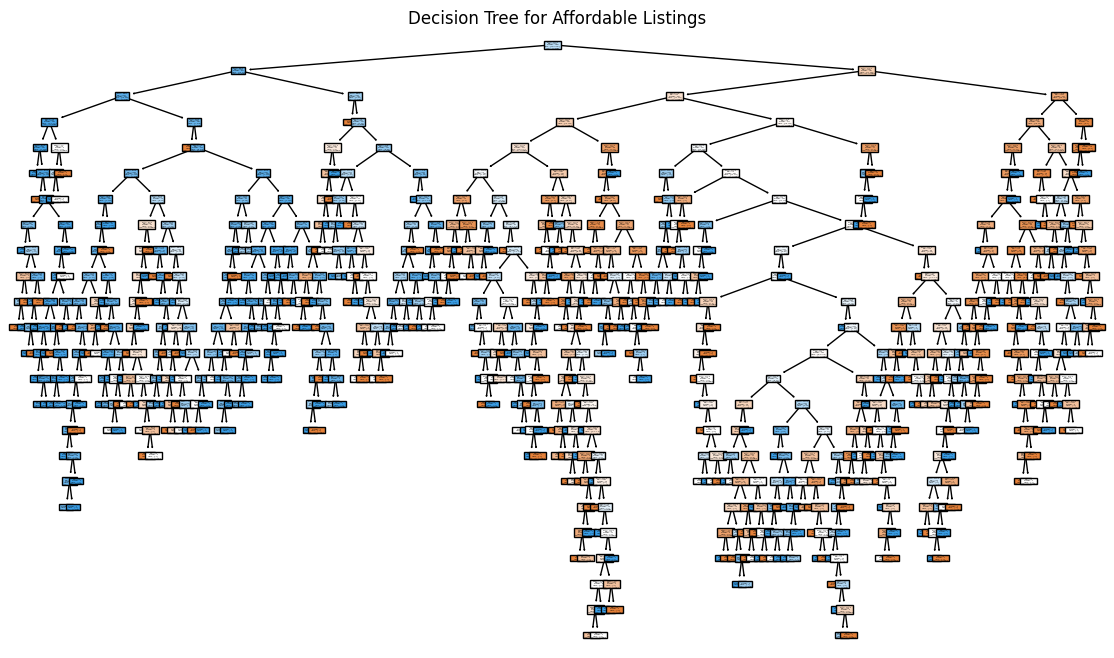

In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Plot decision tree
plt.figure(figsize=(14, 8))
plot_tree(clf, feature_names=X.columns, class_names=['Not Affordable', 'Affordable'], filled=True)
plt.title("Decision Tree for Affordable Listings")
plt.show()

### **🔧 Try It Yourself - Part 4**

4.1. Create a second model called `clf_limited` with `max_depth=3` . In the previous model, we did not specify a maximum depth, a.k.a we left it unrestricted.

4.2. Fit it on the same training data  

4.3. Visualize this new tree

> You’ll compare the accuracy of this smaller tree in the next section


In [ ]:
# 🔧 4.1. Add code here


# 🔧 4.2. Add code here


# 🔧 4.3. Add code here



## **5. Evaluate the Model**

We’ll check how well the tree performed on the test data using:
- Accuracy score
- Confusion matrix

### Why This Matters:
We want to know how often the model is right and what kind of mistakes it makes.


In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix

# Predict on test set
y_pred = clf.predict(X_test)

# Accuracy
acc = accuracy_score(y_test, y_pred)
print("Test Accuracy:", acc)

# Confusion matrix
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))


Test Accuracy: 0.6952141057934509
Confusion Matrix:
 [[ 91  55]
 [ 66 185]]


### 🔧 **Try It Yourself - Part 5**

5.1. Use the `clf_limited` model you created in Part 4 to predict on the test set  

5.2. Calculate and print the **test accuracy** for `clf_limited`  



In [ ]:
# 🔧 5.1. Add code here


# 🔧 5.2. Add code here



5.3. Compare the test accuracy of `clf_limited` to the original `clf`. Which performs better?

### ✍️ Your Response: 🔧

5.3.

## **Part 6: Assess Feature Importance**


We’ll rank the most important predictors.

### Why This Matters:
Tree plots explain the model's logic. Feature importance shows what drives predictions.


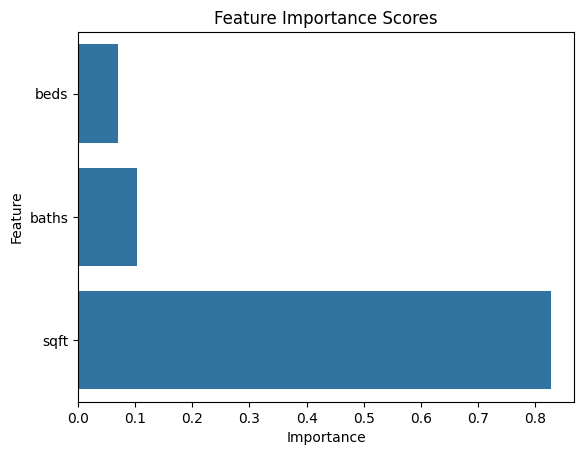

In [ ]:
import seaborn as sns

# Plot feature importance
feat_imp = pd.Series(clf.feature_importances_, index=X.columns)
sns.barplot(x=feat_imp.values, y=feat_imp.index)
plt.title("Feature Importance Scores")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()


### **🔧 Try It Yourself - Part 6**

6.1. Evaluate the importance of features in the smaller tree, `clf_limited`



In [ ]:
# 🔧 6.1. Add code here

6.2. Which feature does it split on first?  

6.3. Is the structure of `clf_limited` simpler or more complex than the original `clf` tree? What about the difference in performance? What does that tell you about the relationship between model complexity and model performance on the test set? Why do you think this happens? HINT: overfitting

### ✍️ Your Response: 🔧

6.2.


6.3.



## **🔧 Part 7: Reflection (100 words or less per question)**

7.1. Which feature was most useful in identifying affordable listings? why do you say that?

7.2. Would you feel confident using this model to recommend pricing to landlords? explain why or not?

### ✍️ Your Response: 🔧

7.1.


7.2.




## Export Your Notebook to Submit in Canvas
- Use the instructions from Lab 1

In [ ]:
!jupyter nbconvert --to html "lab_10_LastnameFirstname.ipynb"